✅ مدل BiLSTM از پوشه 3 با موفقیت لود شد.

در حال پردازش: ./accident_demo_1.mp4 ...


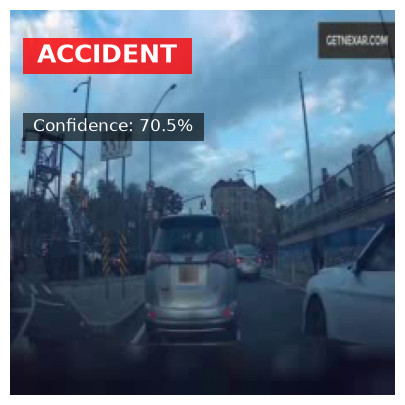


در حال پردازش: ./normal_demo_1.mp4 ...


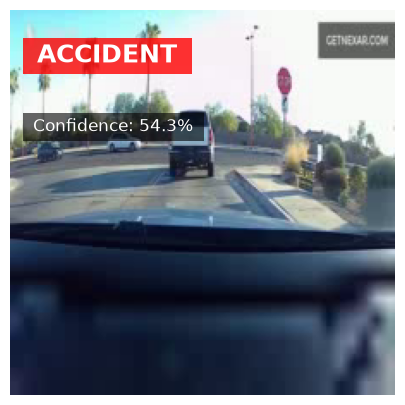

In [1]:
import cv2
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np
import os

# ۱. کلاس دقیق مدل دوطرفه (BiLSTM) مربوط به بخش اصلی پروژه
class AccidentBiLSTM(nn.Module):
    def __init__(self, input_size=512, hidden_size=256, num_layers=1, dropout=0.0):
        super(AccidentBiLSTM, self).__init__()
        self.input_noise = nn.Dropout(p=0.15)
        # دقت کنید که شبکه به صورت دوطرفه (bidirectional=True) تنظیم شده است
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, bidirectional=True)
        self.fc1 = nn.Linear(hidden_size * 2, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.input_noise(x)
        lstm_out, _ = self.lstm(x)
        pooled_out, _ = torch.max(lstm_out, dim=1) 
        x = self.dropout(self.relu(self.fc1(pooled_out)))
        return self.sigmoid(self.fc2(x)).squeeze(-1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ۲. مسیردهی دقیق به مدل نهایی در پوشه ۳
# اگر اسم فایل .pth شما چیز دیگری است، فقط این خط را تغییر دهید
weights_path = '../3/best_final_bilstm.pth' 

if not os.path.exists(weights_path):
    print(f"خطا: فایل {weights_path} پیدا نشد! لطفا مسیر پوشه 3 را چک کنید.")
else:
    # لود کردن هوشمند مدل
    saved_weights = torch.load(weights_path, map_location=device, weights_only=True)
    detected_hidden = saved_weights['fc1.weight'].shape[1] // 2
    detected_layers = sum(1 for k in saved_weights.keys() if k.startswith('lstm.weight_ih_l') and 'reverse' not in k)

    bilstm_model = AccidentBiLSTM(
        input_size=512, 
        hidden_size=detected_hidden, 
        num_layers=detected_layers, 
        dropout=0.0 
    ).to(device)

    bilstm_model.load_state_dict(saved_weights)
    bilstm_model.eval()
    print("✅ مدل BiLSTM از پوشه 3 با موفقیت لود شد.")

# بارگذاری ResNet برای استخراج ویژگی فریم‌ها
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet = nn.Sequential(*list(resnet.children())[:-1]).to(device)
resnet.eval()

# ۳. تابع پیش‌بینی ویدیو
def analyze_dashcam_video(video_path, threshold=0.50):
    print(f"\nدر حال پردازش: {video_path} ...")
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("خطا: ویدیو پیدا نشد!")
        return
        
    fps = cap.get(cv2.CAP_PROP_FPS)
    step = max(1, int(fps / 5)) 
    
    frames_tensor = []
    display_frame = None 
    frame_idx = 0
    
    while True:
        ret, frame = cap.read()
        if not ret: break
            
        if frame_idx % step == 0:
            if display_frame is None:
                display_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                
            rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_t = torch.from_numpy(rgb_frame).permute(2, 0, 1).float() / 255.0
            frame_t = T.Resize((224, 224), antialias=True)(frame_t)
            frames_tensor.append(frame_t)
            
        frame_idx += 1
    cap.release()
    
    if not frames_tensor:
        return
        
    with torch.no_grad():
        video_batch = torch.stack(frames_tensor).to(device)
        features = [resnet(video_batch[i:i+32]).squeeze(-1).squeeze(-1) for i in range(0, len(video_batch), 32)]
        video_features = torch.cat(features, dim=0)
        
        seq_len = video_features.size(0)
        if seq_len < 100:
            padding = torch.zeros(100 - seq_len, 512).to(device)
            video_features = torch.cat((video_features, padding), dim=0)
        else:
            video_features = video_features[:100, :]
            
        # پیش‌بینی نهایی با BiLSTM
        prob = bilstm_model(video_features.unsqueeze(0)).item()
        
    is_accident = prob >= threshold
    label_text = "ACCIDENT" if is_accident else "NORMAL"
    color = "red" if is_accident else "green"
    
    # نمایش فریم اول به همراه نتیجه پیش‌بینی
    plt.figure(figsize=(8, 5))
    plt.imshow(display_frame)
    plt.axis('off')
    plt.text(10, 30, f" {label_text} ", color='white', fontsize=18, fontweight='bold', bbox=dict(facecolor=color, alpha=0.8, edgecolor='none'))
    plt.text(10, 70, f" Confidence: {prob*100:.1f}% ", color='white', fontsize=12, bbox=dict(facecolor='black', alpha=0.6, edgecolor='none'))
    plt.show()

# ۴. اجرای کد روی ویدیوهای تستی
analyze_dashcam_video('./accident_demo_1.mp4')
analyze_dashcam_video('./normal_demo_1.mp4')


در حال پردازش: ./accident_demo_5.mp4 ...


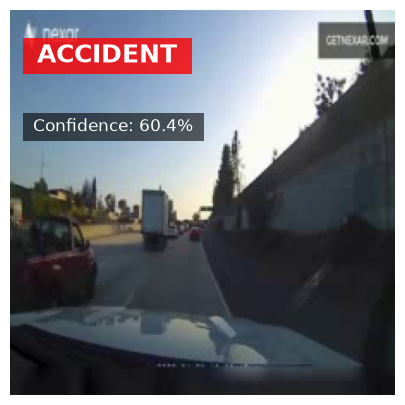


در حال پردازش: ./normal_demo_5.mp4 ...


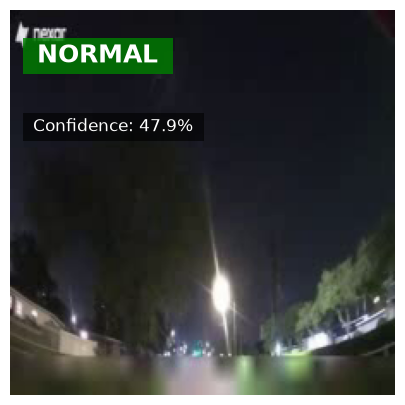

In [5]:
analyze_dashcam_video('./accident_demo_5.mp4')
analyze_dashcam_video('./normal_demo_5.mp4')


در حال پردازش: ./accident_demo_6.mp4 ...


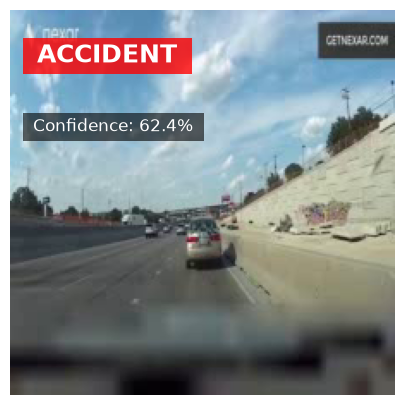


در حال پردازش: ./normal_demo_6.mp4 ...


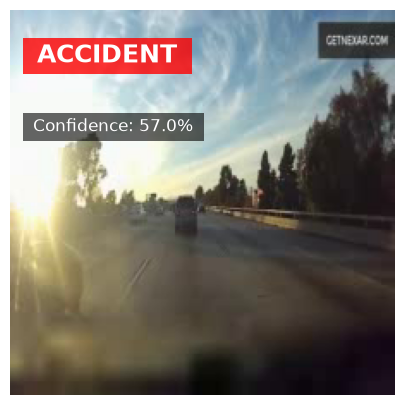

In [6]:
analyze_dashcam_video('./accident_demo_6.mp4')
analyze_dashcam_video('./normal_demo_6.mp4')

dakhele in file video haro be model midim va predict ro anjam midim